# The mouse LDA on the neuromodulator dataset alone

Same embedding as `1_proficient_1cam_ld1` (`lda_shrinkage_core`: missing-data screen, ≥ 3 sessions per
mouse, mouse-weighted shrinkage LDA), fitted on the **NM photometry sessions of the ephys protocol** only,
on NM's **own** syllables (left paw + wheel states fitted on NM, k = 8, whisk, 100 ms lick HMM).

The two state spaces differ, so the NM axes are **not** compared with the BWM LD1 by their loadings. They are
compared by what they **correlate with**, measured with the same definitions in both datasets
(`nm_lda.py`): per-epoch wheel / paw speed and the pre-quiescence / quiescence gate (`vigor/lda`),
epoch durations, RT / accuracy / biases (`lab_controls` trial section), GLM-HMM K = 2 engagement
(`lab_controls` engage section, from the per-mouse NM fits).

Questions:
1. Are NM mice individually identifiable from their syllables?
2. What do the NM LDs track, and do they separate neuromodulator types?
3. Is there a BWM-LD1-like axis among them?

All mice are from one lab (mainenlab): no lab term. **12 mice**: a mouse-level correlation needs |r| ≳ 0.58
for p < 0.05, so single correlates are descriptive; the profile test (3) pools them.
NM LDs are oriented so that **faster RT = higher**, the BWM LD1 convention.

In [1]:
import pickle
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nm_lda as n
import proficient_1cam as pc

warnings.filterwarnings('ignore')
pd.set_option('display.width', 200)
LDS = ['LD1', 'LD2', 'LD3']


def cached(name, make):
    f = n.OUT / f'{name}.pkl'
    if f.exists():
        return pickle.load(open(f, 'rb'))
    n.OUT.mkdir(parents=True, exist_ok=True)
    obj = make()
    pickle.dump(obj, open(f, 'wb'))
    return obj

In [2]:
#%%
""" BUILD: ephys sessions, embedding, session measures (cached in data/neuromodulators/nm_lda/) """
X, mice = n.design('ephys')
emb, sc = pc.embed(X, mice)
sc = sc.drop(columns='lab')
M = n.session_measures(X.index)
n.orient_by(sc, emb, M)
META = n.mouse_meta()
print(emb.describe_cv())
print('share of between-mouse variance per LD:', emb.axis_share.round(3))

proficient design: 119 sessions x 360 features, 12 mice


shrinkage CV (mean +/- SE): 0.05 0.979+/-0.008, 0.1 0.975+/-0.009, 0.2 0.975+/-0.009, 0.3 0.975+/-0.009, 0.5 0.963+/-0.010  -> 0.3 (most regularised within 1 SE of the best)
share of between-mouse variance per LD: [0.258 0.162 0.135 0.115 0.088 0.06  0.057 0.04  0.033 0.028 0.024]


In [3]:
#%%
""" 1. MOUSE IDENTIFICATION: leave-one-session-out, nested shrinkage (as the proficient score) """
loso = cached('loso_ephys', lambda: pc.lc.loso_score(X.to_numpy(), mice.to_numpy(), np.random.default_rng(0)))
lo, hi = pc.lc.mouse_ci(loso['hit'][0], mice.to_numpy())
print(f"accuracy {loso['score']:.3f} [{lo:.3f}, {hi:.3f}] (mice resampled), shuffled {loso['shuffled']:.3f}, "
      f"chance {1 / loso['n_mice']:.3f}; {len(X)} sessions, {loso['n_mice']} mice")
display(sc.groupby('mouse_name').size().rename('sessions').to_frame().join(META).T)

  repeat 1/1: 0.866 (shuffled 0.101)
accuracy 0.866 [0.789, 0.935] (mice resampled), shuffled 0.101, chance 0.083; 119 sessions, 12 mice


mouse_name,ZFM-04019,ZFM-05245,ZFM-08652,ZFM-08751,ZFM-08813,ZFM-08871,ZFM-09139,ZFM-09343,ZFM-09365,ZFM-09394,ZFM-09439,ZFM-09772
sessions,8,10,10,12,5,11,9,12,12,11,12,7
NM,DA,5HT,NE,ACh,ACh,NE,DA,DA,5HT,DA,5HT,ACh
target,SNc-DA,DR-5HT,LC-NE,NBM-ACh,NBM-ACh,LC-NE,SNc-DA,SNc-DA,DR-5HT,VTA-DA,DR-5HT,NBM-ACh


In [4]:
#%%
""" 2a. WHAT EACH LD TRACKS: r across mouse means, p from permuting mice """
corr = n.mouse_corr(sc, M, cols=LDS, n_perm=5000)
(corr.pivot(index='metric', columns='ld', values=['r', 'p_perm'])
     .sort_values(('r', 'LD1')).round(2))

r             p_perm            
ld                           LD1   LD2   LD3    LD1   LD2   LD3
metric                                                         
log_reaction               -0.70 -0.30 -0.02   0.01  0.34  0.96
wheel_gate                 -0.49  0.00  0.47   0.11  0.99  0.12
dur_Choice                 -0.44 -0.04 -0.10   0.16  0.90  0.78
entropy                    -0.39 -0.20  0.21   0.21  0.53  0.49
switches                   -0.29 -0.27  0.52   0.36  0.39  0.09
short_bouts                -0.27 -0.38  0.48   0.39  0.21  0.11
dur_Quiescence             -0.27  0.28 -0.22   0.40  0.39  0.49
paw_speed_Pre-quiescence   -0.24 -0.08  0.64   0.47  0.81  0.02
correct                    -0.22  0.42 -0.38   0.49  0.16  0.23
bias                       -0.17  0.51 -0.07   0.60  0.08  0.82
frac_engaged               -0.12 -0.17 -0.21   0.72  0.61  0.51
paw_gate                   -0.11 -0.05  0.53   0.72  0.89  0.08
wheel_speed_Pre-quiescence -0.10 -0.45  0.62   0.73  0.15  0.02
paw_speed_Quiescence       -0.06  0.04 -0.11   0.85  0.91  0.76
l_paw_band_0.5_8           -0.02 -0.04  0.57   0.95  0.86  0.04
l_paw_mean_speed_moving     0.01 -0.10  0.71   0.97  0.76  0.01
dur_Pre-quiescence          0.02 -0.37  0.28   0.95  0.24  0.38
choice_bias                 0.03 -0.56 -0.02   0.93  0.06  0.95
wheel_mean_speed_moving     0.11 -0.38  0.50   0.72  0.22  0.09
paw_speed_ITI               0.21 -0.05  0.56   0.52  0.87  0.06
l_paw_mean_speed            0.21 -0.18  0.60   0.51  0.57  0.04
p_stay_eng                  0.24  0.07 -0.58   0.45  0.83  0.05
p_stay_dis                  0.29  0.44 -0.42   0.37  0.16  0.18
n_trials                    0.30 -0.36 -0.22   0.36  0.25  0.49
wheel_speed_ITI             0.35 -0.42  0.47   0.27  0.18  0.12
wheel_mean_speed            0.37 -0.46  0.49   0.24  0.14  0.11
paw_speed_Choice            0.42 -0.09  0.27   0.16  0.79  0.40
dur_ITI                     0.51  0.13 -0.34   0.09  0.68  0.28
l_paw_frac_moving           0.53 -0.25  0.25   0.09  0.43  0.44
wheel_bout_rate_per_min     0.54  0.03 -0.28   0.07  0.93  0.38
wheel_speed_Quiescence      0.55 -0.24 -0.13   0.06  0.45  0.70
wheel_frac_moving           0.61 -0.38  0.36   0.03  0.23  0.25
wheel_speed_Choice          0.61  0.03 -0.11   0.04  0.92  0.73

LD1: Kruskal-Wallis across NM types p = 0.920
LD2: Kruskal-Wallis across NM types p = 0.729
LD3: Kruskal-Wallis across NM types p = 0.036


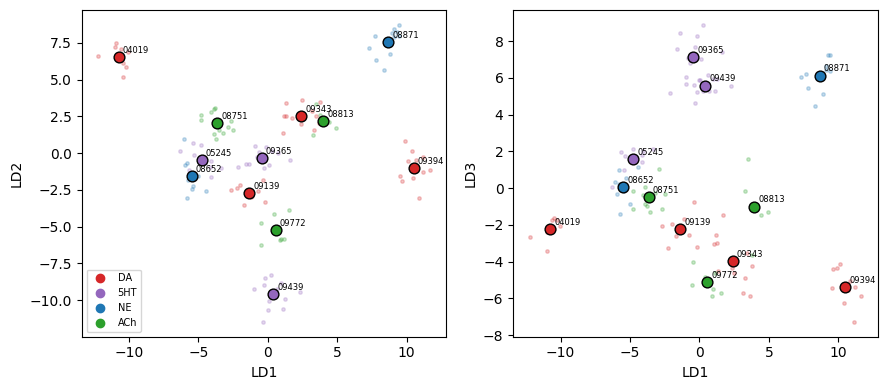

,LD1,LD2,LD3,NM,target
mouse_name,,,,,
ZFM-04019,-10.75,6.55,-2.23,DA,SNc-DA
ZFM-08652,-5.50,-1.58,0.06,NE,LC-NE
ZFM-05245,-4.77,-0.47,1.59,5HT,DR-5HT
ZFM-08751,-3.65,2.04,-0.50,ACh,NBM-ACh
ZFM-09139,-1.36,-2.69,-2.25,DA,SNc-DA
ZFM-09365,-0.44,-0.31,7.14,5HT,DR-5HT
ZFM-09439,0.40,-9.61,5.58,5HT,DR-5HT
ZFM-09772,0.56,-5.23,-5.13,ACh,NBM-ACh
ZFM-09343,2.40,2.53,-3.98,DA,SNc-DA


In [5]:
#%%
""" 2b. NEUROMODULATOR TYPE ON THE LDs (descriptive: 2-4 mice per type) """
from scipy.stats import kruskal
mm = sc.groupby('mouse_name')[LDS].mean().join(META)
for c in LDS:
    print(f"{c}: Kruskal-Wallis across NM types p = {kruskal(*[g[c] for _, g in mm.groupby('NM')]).pvalue:.3f}")
COL = {'DA': '#d62728', '5HT': '#9467bd', 'NE': '#1f77b4', 'ACh': '#2ca02c'}
fig, ax = plt.subplots(1, 2, figsize=(9, 4))
for a, (x, y) in zip(ax, [('LD1', 'LD2'), ('LD1', 'LD3')]):
    for s, g in sc.join(META, on='mouse_name').groupby('mouse_name'):
        a.scatter(g[x], g[y], s=6, alpha=.25, color=COL[g['NM'].iloc[0]])
    for s, r in mm.iterrows():
        a.scatter(r[x], r[y], s=60, color=COL[r['NM']], edgecolor='k', zorder=3)
        a.annotate(s.replace('ZFM-', ''), (r[x], r[y]), fontsize=6, xytext=(3, 3), textcoords='offset points')
    a.set_xlabel(x); a.set_ylabel(y)
ax[0].legend(handles=[plt.Line2D([], [], marker='o', ls='', color=c, label=k) for k, c in COL.items()], fontsize=7)
plt.tight_layout(); plt.show()
mm.sort_values('LD1').round(2)

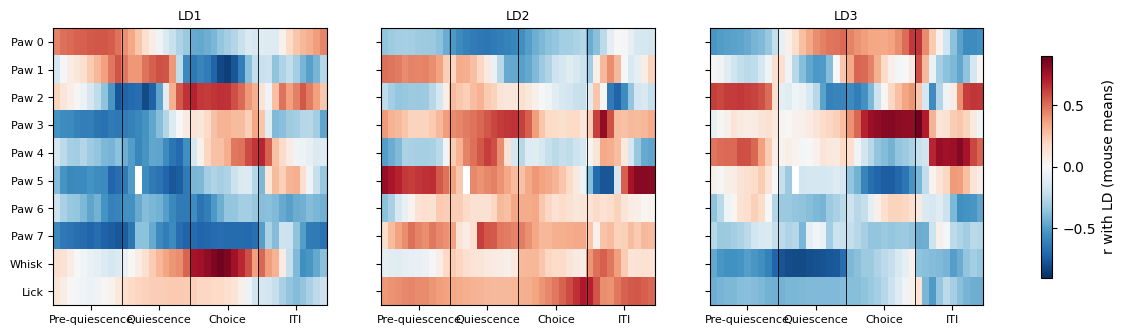

Paw 0  Paw 1  Paw 2  Paw 3  Paw 4  Paw 5  Paw 6  Paw 7  Whisk  Lick
LD1 Pre-quiescence   0.52   0.21  -0.17  -0.61  -0.31  -0.57  -0.42  -0.69  -0.02  0.02
    Quiescence       0.02   0.30  -0.27  -0.35  -0.55  -0.65  -0.51  -0.58   0.24  0.21
    Choice          -0.32  -0.62   0.57   0.24   0.31  -0.27  -0.45  -0.69   0.72  0.10
    ITI              0.16  -0.31   0.33  -0.25   0.13   0.04  -0.42  -0.44  -0.12 -0.26
LD2 Pre-quiescence  -0.34   0.42  -0.26   0.27  -0.31   0.65   0.00   0.39  -0.04  0.41
    Quiescence      -0.61   0.02   0.21   0.54   0.36   0.38   0.21   0.38   0.12  0.31
    Choice          -0.38  -0.27  -0.06   0.27  -0.18   0.25   0.21   0.35   0.19  0.48
    ITI             -0.17   0.08  -0.26   0.40  -0.03   0.10   0.11   0.23   0.30  0.53
LD3 Pre-quiescence  -0.43  -0.11   0.56   0.07   0.43   0.10  -0.02  -0.24  -0.55 -0.41
    Quiescence       0.31  -0.22  -0.30   0.11   0.06  -0.18  -0.35  -0.21  -0.77 -0.40
    Choice           0.42   0.24  -0.11   0.72  -0.24  -0.61   0.02  -0.32  -0.23 -0.23
    ITI             -0.14  -0.12   0.16   0.29   0.53   0.09  -0.30  -0.24  -0.39 -0.34

In [6]:
#%%
""" 2c. LOADINGS in NM's own state space (structure coefficients; paw states vigor-numbered, 0 = stillest) """
EPOCHS = n.EPOCHS
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6), sharey=True)
for a, ld in zip(ax, LDS):
    L = pc.loading_profile(sc, X, ld)
    im = a.imshow(L.T, aspect='auto', cmap='RdBu_r', vmin=-.9, vmax=.9)
    for e in (10, 20, 30):
        a.axvline(e - .5, color='k', lw=.6)
    a.set_xticks([5, 15, 25, 35]); a.set_xticklabels(EPOCHS, fontsize=8)
    a.set_yticks(range(L.shape[1])); a.set_yticklabels(L.columns, fontsize=8)
    a.set_title(ld, fontsize=9)
fig.colorbar(im, ax=ax, label='r with LD (mouse means)', shrink=.8)
plt.show()
pd.concat({ld: pc.loading_profile(sc, X, ld).groupby(np.repeat(EPOCHS, 10), sort=False).mean()
           for ld in LDS}).round(2)

,ld,profile_r,null_95,p,n_measures,n_mice
0,LD1,0.565,0.697,0.155,31,12
1,LD2,0.144,0.699,0.598,31,12
2,LD3,-0.517,0.705,0.973,31,12


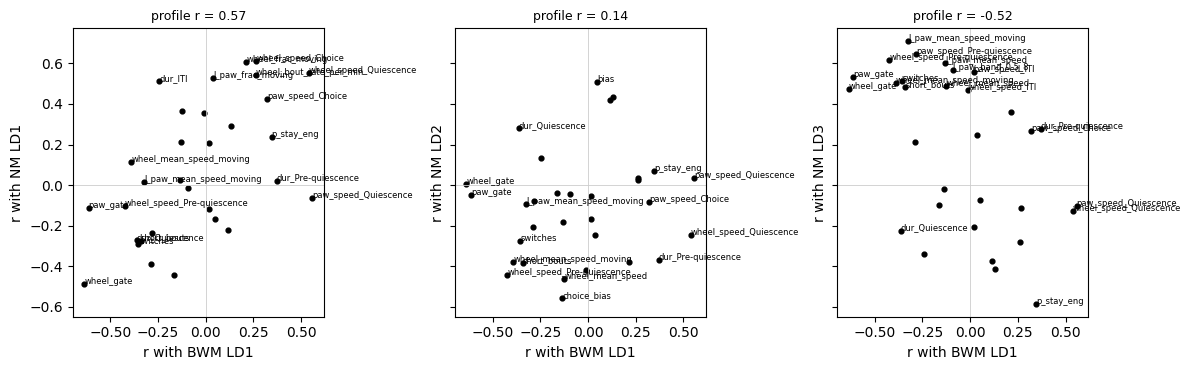

In [7]:
#%%
""" 3. IS THERE A BWM-LD1-LIKE AXIS? correlate profile of each NM LD vs that of the BWM 1-camera LD1.
Null: NM mouse labels permuted (re-oriented by RT each time), so the measures' intercorrelations are kept. """
BWM = n.bwm_ld1_profile()
prof = n.profile_test(sc, M, BWM, cols=LDS)
display(prof.round(3))
P = corr.pivot(index='metric', columns='ld', values='r').join(BWM, how='inner').drop(index='log_reaction')
fig, ax = plt.subplots(1, 3, figsize=(12, 3.8), sharex=True, sharey=True)
for a, ld in zip(ax, LDS):
    a.axhline(0, color='.8', lw=.6); a.axvline(0, color='.8', lw=.6)
    a.scatter(P['BWM LD1'], P[ld], s=12, color='k')
    for m, r in P.iterrows():
        if abs(r['BWM LD1']) > .3 or abs(r[ld]) > .45:
            a.annotate(m, (r['BWM LD1'], r[ld]), fontsize=6)
    a.set_xlabel('r with BWM LD1'); a.set_ylabel(f'r with NM {ld}')
    a.set_title(f"profile r = {prof.set_index('ld').loc[ld, 'profile_r']:.2f}", fontsize=9)
plt.tight_layout(); plt.show()

In [8]:
#%%
""" ROBUSTNESS: the same with the biased-protocol NM sessions included (more mice, two protocols) """
Xa, mice_a = n.design(None)
emb_a, sc_a = pc.embed(Xa, mice_a)
sc_a = sc_a.drop(columns='lab')
Ma = n.session_measures(Xa.index)
n.orient_by(sc_a, emb_a, Ma)
print(emb_a.describe_cv())
display(n.profile_test(sc_a, Ma, BWM, cols=LDS).round(3))
ca = n.mouse_corr(sc_a, Ma, cols=('LD1',), n_perm=2000).set_index('metric')
ca[['n_mice', 'r', 'p_perm']].join(corr[corr.ld == 'LD1'].set_index('metric')['r'].rename('r ephys only'))\
    .join(BWM).sort_values('BWM LD1').round(2)

proficient design: 479 sessions x 360 features, 30 mice


shrinkage CV (mean +/- SE): 0.05 0.808+/-0.012, 0.1 0.807+/-0.012, 0.2 0.828+/-0.012, 0.3 0.833+/-0.012, 0.5 0.822+/-0.013  -> 0.3 (most regularised within 1 SE of the best)


,ld,profile_r,null_95,p,n_measures,n_mice
0,LD1,0.680,0.730,0.089,31,30
1,LD2,0.317,0.733,0.517,31,30
2,LD3,0.079,0.728,0.724,31,30


,n_mice,r,p_perm,r ephys only,BWM LD1
metric,,,,,
wheel_gate,30,-0.77,0.00,-0.49,-0.64
paw_gate,30,-0.29,0.12,-0.11,-0.61
log_reaction,30,-0.79,0.00,-0.70,-0.55
wheel_speed_Pre-quiescence,30,-0.31,0.10,-0.10,-0.42
wheel_mean_speed_moving,30,-0.15,0.45,0.11,-0.39
dur_Quiescence,30,-0.57,0.00,-0.27,-0.36
switches,30,0.00,0.99,-0.29,-0.36
short_bouts,30,-0.08,0.70,-0.27,-0.34
l_paw_mean_speed_moving,30,0.03,0.89,0.01,-0.32


## Reading

- **NM mice are identifiable**: LOSO 0.87 [0.79, 0.94] for 12 mice (chance 0.08, shuffled 0.10). Not
  comparable with the proficient 0.86 at face value: 12 classes are easier than 58.
- **Neuromodulator type does not organise the space**: LD1 and LD2 p > 0.7 across types; LD3 p = 0.04
  uncorrected (3 tests, 2-4 mice per type), i.e. nothing to lean on. Mouse variability here is not "which
  neuromodulator", as it should not be: the fiber does not change behaviour.
- **NM LD1** (26 % of between-mouse variance; oriented fast-RT = high): fast RT (r = −0.70), more wheel
  movement during quiescence and choice, a weaker pre-quiescence / quiescence wheel gate (−0.49).
  **NM LD3** is the movement-amplitude axis (paw speed while moving 0.71, pre-quiescence speeds ≈ 0.6),
  not RT; NM LD2 has no clear correlate.
- **Is NM LD1 the BWM LD1?** Its correlate profile resembles the BWM LD1's (r = 0.57 across 31 measures;
  0.68 with the biased sessions added, 30 mice), but **not more than chance**: p = 0.16 / 0.09 against
  permuted mouse orderings. The null is high (95th percentile ≈ 0.7) because the measures are intercorrelated
  and orienting by RT already drags the gate and quiescence speeds along. So: consistent with the same axis,
  not evidence for it.
- With the biased sessions included, LD1 becomes a broad "moves a lot" axis (wheel / paw fraction moving
  ≈ 0.9, more trials, more accurate); some of that may be protocol mix differing between mice.

What this leaves for the projection step: the NM data alone cannot establish that its main axis of mouse
variability is the BWM LD1; with 12 (or 30) mice, a fixed BWM frame is the more powerful test.